# Explainable predictive maintenance on NASA C-MAPSS: walkthrough

This notebook runs the pipeline step by step on subset FD001 (100 training engines run to failure, 100 test engines still in service):

1. predict remaining useful life (RUL) with an uncertainty band;
2. replay the predictions through a maintenance policy to obtain a **simulated** maintenance event log, and mine it;
3. rank the in-service fleet for inspection with TOPSIS, and explain each position.

The sensor data are NASA's (Saxena et al., 2008). The maintenance event log is simulated by `xpdm.eventlog`: C-MAPSS has no maintenance records.

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from xpdm.data import download, load_cmapss, add_rul
from xpdm.features import build_features, feature_columns, informative_sensors, last_cycle, health_index, degradation_rate
from xpdm.model import RULModel, out_of_fold, rmse, phm_score
from xpdm import eventlog, processmining, mcda, explain

DATA_DIR = "../data"
download(DATA_DIR)  # official NASA archive; see README for a mirror option
train, test, rul_true = load_cmapss("FD001", DATA_DIR)
train = add_rul(train, clip=125)
sensors = informative_sensors(train)
print(len(train), "training rows;", train.unit.nunique(), "engines; informative sensors:", sensors)

20631 training rows; 100 engines; informative sensors: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 1. Remaining useful life with an 80% band

Gradient boosting on rolling means, standard deviations and slopes. Cross-validation is grouped by engine, so no engine appears in both training and validation folds.

CV RMSE 16.3 | test RMSE 17.4 | PHM score 866 | 80% band coverage 76%


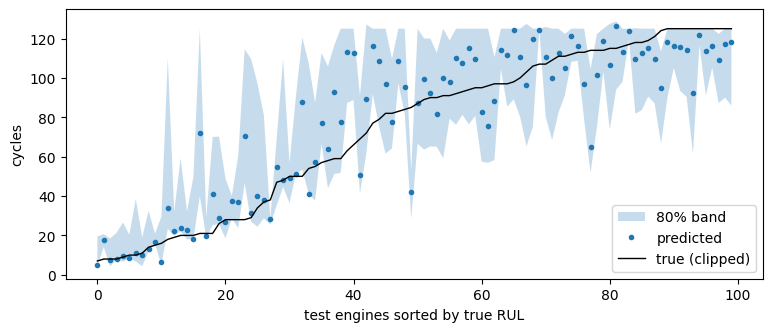

In [2]:
F = build_features(train, sensors); cols = feature_columns(F)
oof = out_of_fold(F, cols)
model = RULModel().fit(F[cols], F["rul"])
T_all = build_features(test, sensors)
T_all = pd.concat([T_all, model.predict(T_all[cols])], axis=1)
snap = last_cycle(T_all); y = rul_true.loc[snap.index].clip(upper=125)
print(f"CV RMSE {rmse(oof.rul, oof.point):.1f} | test RMSE {rmse(y, snap.point):.1f} | PHM score {phm_score(y, snap.point):.0f} | "
      f"80% band coverage {((y >= snap.lower) & (y <= snap.upper)).mean():.0%}")
o = np.argsort(y.values)
plt.figure(figsize=(9, 3.5))
plt.fill_between(range(100), snap.lower.values[o], snap.upper.values[o], alpha=.25, label="80% band")
plt.plot(snap.point.values[o], ".", label="predicted"); plt.plot(y.values[o], "k-", lw=1, label="true (clipped)")
plt.xlabel("test engines sorted by true RUL"); plt.ylabel("cycles"); plt.legend(); plt.show()

## 2. A simulated maintenance log and what process mining shows

The policy raises an alert when the pessimistic RUL drops below 25 cycles, may have a planner dismiss it, then schedules and performs an inspection before a planned removal. Delays are random within stated bounds. An engine whose real failure comes first is logged as an unplanned removal.

,variant,cases
0,Monitoring started → Degradation alert → Inspe...,82
1,Monitoring started → Degradation alert → Alert...,9
2,Monitoring started → Degradation alert → Alert...,5
3,Monitoring started → Degradation alert → Inspe...,3
4,Monitoring started → Degradation alert → Inspe...,1


mean fitness against the reference process: 0.935


,case_id,fitness,conforms,deviations
9,engine_010,0.750000,False,Degradation alert → Alert dismissed; Alert dis...
18,engine_019,0.750000,False,Degradation alert → Alert dismissed; Alert dis...
29,engine_030,0.428571,False,Degradation alert → Alert dismissed; Alert dis...
31,engine_032,0.750000,False,Degradation alert → Alert dismissed; Alert dis...
39,engine_040,0.750000,False,Degradation alert → Alert dismissed; Alert dis...


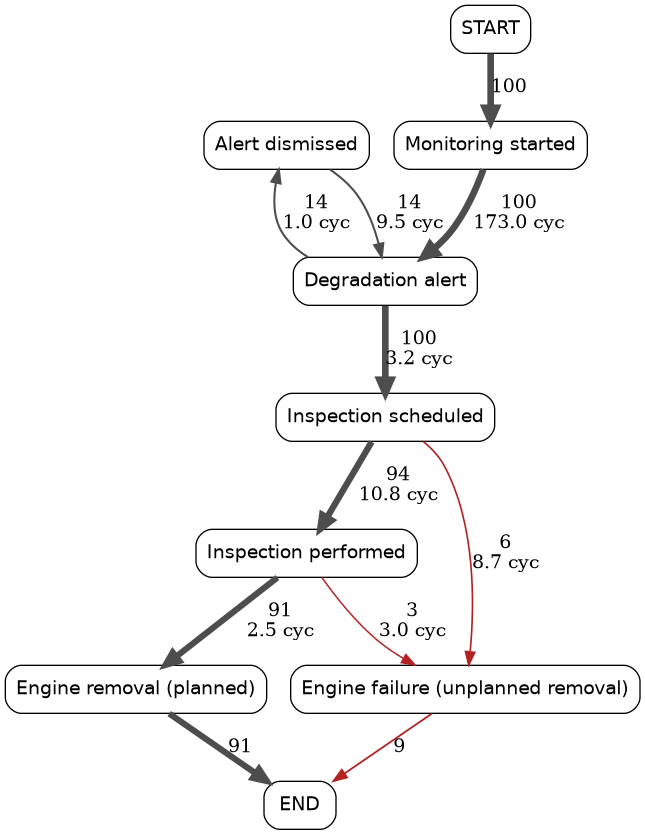

In [3]:
log = eventlog.simulate(oof)
display(processmining.variants(log))
conf = processmining.conformance(log)
print(f"mean fitness against the reference process: {conf.fitness.mean():.3f}")
display(conf[~conf.conforms].head())
processmining.render_dfg(processmining.dfg(log), "dfg.png")
from IPython.display import Image; Image("dfg.png", width=420)

## 3. Ranking the in-service fleet and explaining the ranking

Criteria, in priority order: pessimistic RUL (lower = more urgent), health-index degradation rate, and open process deviations from the live log (dismissed or pending alerts). Weights are rank-order centroid weights from that order. CRITIC weights are shown for comparison.

In [4]:
live = eventlog.simulate(T_all[["unit", "cycle", "lower"]], in_service=True)
last = live.groupby("case_id").activity.last()
devs = (live[live.activity == "Alert dismissed"].groupby("case_id").size().reindex(last.index, fill_value=0)
        + (last == "Degradation alert").astype(int))
hi = health_index(test, train, sensors)
crit = pd.DataFrame({"rul_lower": snap.lower,
                     "degradation_rate": degradation_rate(test, hi).reindex(snap.index),
                     "process_deviations": devs.rename(lambda c: int(c.split("_")[1])).reindex(snap.index, fill_value=0)})
benefit = {"rul_lower": False, "degradation_rate": True, "process_deviations": True}
w = mcda.roc_weights(list(benefit)); w_critic = mcda.critic_weights(crit, benefit)
display(pd.DataFrame({"ROC (default)": w, "CRITIC": w_critic}).round(3))
rank = mcda.topsis(crit, w, benefit).join(mcda.sensitivity(crit, w, benefit)).join(crit).join(rul_true)
urgent = set(rul_true[rul_true <= 30].index)
for name, idx in [("TOPSIS, ROC weights", rank.index), ("TOPSIS, CRITIC weights", mcda.topsis(crit, w_critic, benefit).index),
                  ("predicted RUL only", snap.point.sort_values().index)]:
    print(f"{name:24s} truly urgent engines (true RUL <= 30) in top 10: {len(set(idx[:10]) & urgent)}/10")
rank.head(10).round(3)

,ROC (default),CRITIC
rul_lower,0.611,0.297
degradation_rate,0.278,0.319
process_deviations,0.111,0.384


TOPSIS, ROC weights      truly urgent engines (true RUL <= 30) in top 10: 9/10
TOPSIS, CRITIC weights   truly urgent engines (true RUL <= 30) in top 10: 8/10
predicted RUL only       truly urgent engines (true RUL <= 30) in top 10: 10/10


,closeness,rank,share_rul_lower,share_degradation_rate,share_process_deviations,top_stability,rul_lower,degradation_rate,process_deviations,rul_true
unit,,,,,,,,,,
41,0.771,1,0.625,0.143,0.232,1.000,23.264,0.037,1,18
56,0.728,2,0.703,0.070,0.227,0.950,15.845,0.026,1,15
77,0.709,3,0.665,0.082,0.253,0.825,24.396,0.027,1,34
76,0.695,4,0.680,0.320,0.000,1.000,8.378,0.062,0,10
68,0.687,5,0.723,0.277,0.000,1.000,7.862,0.056,0,8
34,0.685,6,0.761,0.239,0.000,1.000,4.374,0.052,0,7
100,0.679,7,0.632,0.368,0.000,0.940,18.086,0.063,0,20
42,0.677,8,0.769,0.231,0.000,1.000,6.793,0.050,0,10
82,0.669,9,0.797,0.203,0.000,0.875,6.645,0.046,0,9


**Reading the comparison.** On C-MAPSS alone, sorting by predicted RUL is already a strong ranking, and the multicriteria layer cannot beat it on that one measure. Its value is elsewhere: it makes the priority logic explicit and lets planners add criteria the model does not know (operational criticality, spare-engine availability, hangar slots; see `--context` in the CLI). It also surfaces cases such as an engine with a pending, undismissed alert that a pure RUL sort would place lower. The data-driven CRITIC weights do worse because they reward criteria for being variable, not for being important. Weights are a decision to state, not a statistic to estimate.

In [5]:
healthy = F[F.rul >= 125][cols]
imp = model.importance(F[cols].sample(4000, random_state=0), F.rul.sample(4000, random_state=0))
for u, row in rank.head(5).iterrows():
    print("-", explain.rationale(u, row, crit, w, len(rank)),
          "Sensor evidence:", "; ".join(explain.sensor_deviations(snap.loc[u], healthy, list(imp.index[:8]))))

- Engine 41 is ranked 1 of 100 (closeness 0.771). The ranking is driven mainly by its pessimistic (10th percentile) RUL of 23.3 cycles (weight 0.61; more urgent than 82% of the fleet) and its open process deviations of 1.0 (weight 0.11; more urgent than 96% of the fleet). Sensor evidence: s14_mean is -2.9 sd from the healthy baseline; s9_mean is -2.5 sd from the healthy baseline; s4_mean is +2.2 sd from the healthy baseline
- Engine 56 is ranked 2 of 100 (closeness 0.728). The ranking is driven mainly by its pessimistic (10th percentile) RUL of 15.8 cycles (weight 0.61; more urgent than 89% of the fleet) and its open process deviations of 1.0 (weight 0.11; more urgent than 96% of the fleet). Sensor evidence: s21_mean is -4.2 sd from the healthy baseline; s4_mean is +4.1 sd from the healthy baseline; s15_mean is +4.1 sd from the healthy baseline
- Engine 77 is ranked 3 of 100 (closeness 0.709). The ranking is driven mainly by its pessimistic (10th percentile) RUL of 24.4 cycles (weight 

## Optional: a generative-AI summary that must stay grounded

`xpdm.llm.recommend()` asks a language model to write the recommendation from the trade-off table only, and `grounding_check()` lists any number in its answer that is not in the table. Run `xpdm --llm` with `pip install anthropic` and `ANTHROPIC_API_KEY` set. It is off by default, and the pipeline does not depend on it.